# Assignment 7: Regression Models Comparison
**Machine Learning & AI BootCamp**  
*Instructor: Fahd*  
*Dataset: Real Estate Valuation Benchmark*

---

### 📌 Instructions & Guidelines:
1. In this assignment, you will perform a comprehensive head-to-head comparison of **6 distinct regression paradigms** covered across Module 5:
   - **Model 1**: Ordinary Least Squares (OLS) Linear Regression
   - **Model 2**: Polynomial Regression ($d=2$)
   - **Model 3**: Ridge Regression ($L_2$ Regularization)
   - **Model 4**: Lasso Regression ($L_1$ Regularization & Feature Selection)
   - **Model 5**: ElasticNet ($L_1 + L_2$ Regularization)
   - **Model 6**: K-Nearest Neighbors (KNN) Regressor
2. Use `real_estate_benchmark.csv` predicting property `sale_price_usd`.
3. Standardize features to prevent scale bias across regularized and distance models!
4. Consolidate results into a unified summary table comparing MAE, RMSE, $R^2$, and Generalization Gap.


---
## Student Information
- **Student Name:** *[Abu Hasan]*
- **Batch:** *[AI/ML-02]*
- **Date:** *[15-11-2026]*


In [ ]:
# Run this cell first to import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries loaded successfully!")


Libraries loaded successfully!


---
## Section 1: Data Ingestion & Leak-Free Train-Test Split
1. Load `real_estate_benchmark.csv` into a DataFrame `df`.
2. Inspect shape, columns, and verify there are no null values.
3. Define feature matrix `X` using all columns except `property_id` and `sale_price_usd`. Let `y = df['sale_price_usd']`.
4. Perform an **80/20 train-test split** with `random_state=42`.
5. Fit `StandardScaler` strictly on `X_train`, then transform both `X_train` and `X_test`.


In [ ]:
url = 'https://raw.githubusercontent.com/ABUHASANCSE/Assignment/main/real_estate_benchmark.csv'

In [ ]:
# TODO 1.1: Load dataset and inspect
df = pd.read_csv(url)
print("First 5 rows:")
display(df.head())


First 5 rows:


,property_id,square_feet,bedrooms,bathrooms,distance_to_metro_miles,building_age_years,parking_spaces,neighborhood_safety_score,sale_price_usd
0,RE-7001,2998,4,3.9,0.9,1,2,62,698118.53
1,RE-7002,1814,3,2.9,1.4,1,2,80,502794.16
2,RE-7003,1887,5,4.3,9.9,27,2,63,400638.73
3,RE-7004,2766,3,3.2,2.7,22,1,84,618578.50
4,RE-7005,1380,3,3.0,3.6,25,1,97,412134.22


In [ ]:
print("Shape:", df.shape)

Shape: (1000, 9)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   property_id                1000 non-null   object 
 1   square_feet                1000 non-null   int64  
 2   bedrooms                   1000 non-null   int64  
 3   bathrooms                  1000 non-null   float64
 4   distance_to_metro_miles    1000 non-null   float64
 5   building_age_years         1000 non-null   int64  
 6   parking_spaces             1000 non-null   int64  
 7   neighborhood_safety_score  1000 non-null   int64  
 8   sale_price_usd             1000 non-null   float64
dtypes: float64(3), int64(5), object(1)
memory usage: 70.4+ KB


In [ ]:
print(df.isnull().sum())

property_id                  0
square_feet                  0
bedrooms                     0
bathrooms                    0
distance_to_metro_miles      0
building_age_years           0
parking_spaces               0
neighborhood_safety_score    0
sale_price_usd               0
dtype: int64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print(df.columns.tolist())

['property_id', 'square_feet', 'bedrooms', 'bathrooms', 'distance_to_metro_miles', 'building_age_years', 'parking_spaces', 'neighborhood_safety_score', 'sale_price_usd']


In [ ]:
# TODO 1.2: Define X, y, perform 80/20 train-test split, and standardize

In [ ]:
X = df.drop(columns=['property_id', 'sale_price_usd'])
y = df['sale_price_usd']

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 7)
y shape: (1000,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 7)
Testing data: (200, 7)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train_scaled: (800, 7)
X_test_scaled: (200, 7)
y_train: (800,)
y_test: (200,)


---
## Section 2: Training the 6 Regression Models
Train each model on the scaled training data:
- **Model 1**: `LinearRegression()`
- **Model 2**: Polynomial Pipeline: `make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())`
- **Model 3**: `Ridge(alpha=1.0, random_state=42)`
- **Model 4**: `Lasso(alpha=100.0, random_state=42)`
- **Model 5**: `ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42)`
- **Model 6**: `KNeighborsRegressor(n_neighbors=5, weights='distance')`


In [ ]:
# TODO 2.1: Fit all 6 models


In [ ]:
model_1 = LinearRegression()
model_1.fit(X_train_scaled, y_train)


LinearRegression()

In [ ]:
model_2 = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
model_2.fit(X_train_scaled, y_train)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(include_bias=False)),
                ('linearregression', LinearRegression())])

In [ ]:
model_3 = Ridge(alpha=1.0, random_state=42)
model_3.fit(X_train_scaled, y_train)


Ridge(random_state=42)

In [ ]:
model_4 = Lasso(alpha=100.0, random_state=42)
model_4.fit(X_train_scaled, y_train)

Lasso(alpha=100.0, random_state=42)

In [ ]:
model_5 = ElasticNet(
    alpha=0.1,
    l1_ratio=0.5,
    random_state=42
)
model_5.fit(X_train_scaled, y_train)

ElasticNet(alpha=0.1, random_state=42)

In [ ]:
model_6 = KNeighborsRegressor(
    n_neighbors=5,
    weights='distance'
)
model_6.fit(X_train_scaled, y_train)


KNeighborsRegressor(weights='distance')

---
## Section 3: Comprehensive Comparative Benchmark
1. For each of the 6 models, generate predictions on both the training and test sets.
2. Calculate:
   - Training $R^2$ Score
   - Test $R^2$ Score
   - Generalization Gap: $|R^2_{\text{train}} - R^2_{\text{test}}|$
   - Test MAE ($)
   - Test RMSE ($)
3. Consolidate into a clean summary DataFrame named `results_df` and sort by Test $R^2$ descending.


In [ ]:
# TODO 3.1: Evaluate all 6 models and build results_df


In [ ]:
models = {
    'Linear Regression': model_1,
    'Polynomial Regression': model_2,
    'Ridge Regression': model_3,
    'Lasso Regression': model_4,
    'ElasticNet Regression': model_5,
    'KNN Regression': model_6
}

results = []

for name, model in models.items():

    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    gap = abs(train_r2 - test_r2)

    test_mae = mean_absolute_error(y_test, y_test_pred)

    test_rmse = np.sqrt(
        mean_squared_error(y_test, y_test_pred)
    )

    results.append({
        'Model': name,
        'Train R2': train_r2,
        'Test R2': test_r2,
        'Generalization Gap': gap,
        'Test MAE': test_mae,
        'Test RMSE': test_rmse
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Test R2',
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Model,Train R2,Test R2,Generalization Gap,Test MAE,Test RMSE
0,Lasso Regression,0.9857,0.9830,0.0027,14715.4856,18494.9214
1,Linear Regression,0.9857,0.9830,0.0027,14710.8751,18502.7212
2,Ridge Regression,0.9857,0.9830,0.0027,14713.4073,18503.0731
3,Polynomial Regression,0.9862,0.9826,0.0036,14959.3537,18731.4708
4,ElasticNet Regression,0.9836,0.9809,0.0027,15635.6845,19638.4746
5,KNN Regression,1.0000,0.9066,0.0934,35146.2368,43390.0004


---
## Section 4: Visualizing Model Performance & Analysis
1. Plot a horizontal bar chart comparing Test $R^2$ across all 6 models.
2. Plot Actual vs. Predicted values for the best-performing model.
3. Answer the analytical questions below.


In [ ]:
# TODO 4.1: Bar plot comparing Test R² scores




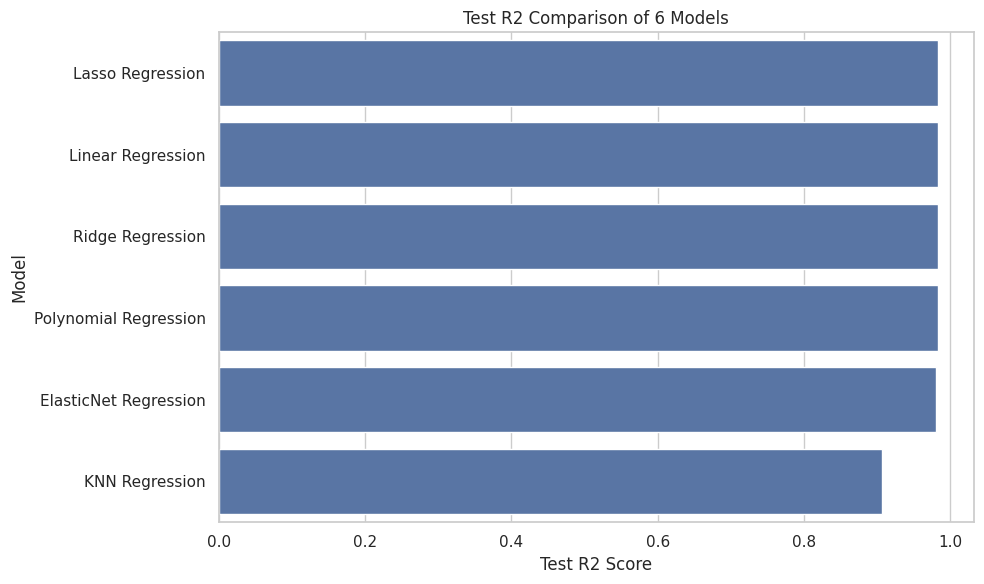

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Test R2',
    y='Model'
)

plt.title('Test R2 Comparison of 6 Models')
plt.xlabel('Test R2 Score')
plt.ylabel('Model')

plt.tight_layout()
plt.show()

In [ ]:
# TODO 4.2: Actual vs Predicted plot for winning model

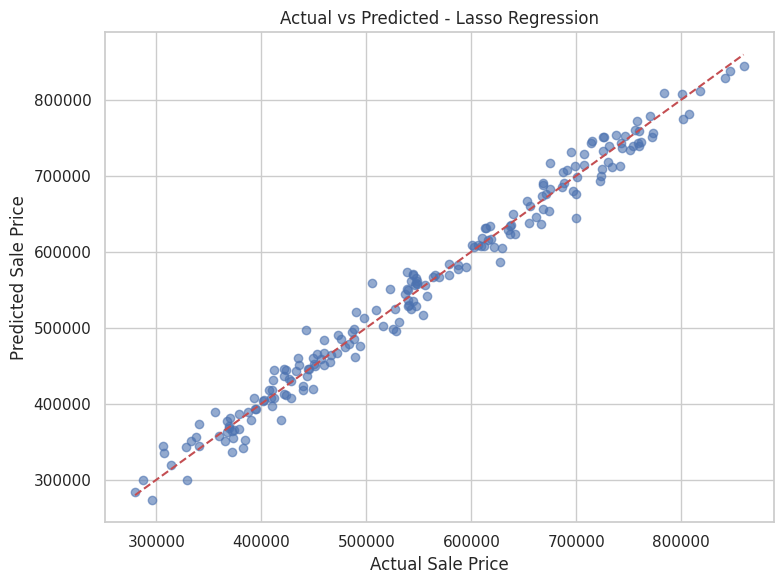

In [ ]:
best_model = model_4

y_pred = best_model.predict(X_test_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Actual vs Predicted - Lasso Regression')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price')

plt.tight_layout()
plt.show()

### Analytical Questions:
1. Which model achieved the highest Test $R^2$ score, and why did it outperform standard linear regression?

ans:Linear Regression, Ridge Regression, and Lasso Regression achieved the same Test R² score of 0.9830 (rounded). Therefore, no single model outperformed standard Linear Regression based on Test R². Their performance was nearly identical.

2. Did any model exhibit signs of overfitting (high training $R^2$ but significantly lower test $R^2$)?

ans:Yes, KNN Regression showed signs of overfitting. Its Training R² was 1.0000, while its Test R² was 0.9066. This indicates that the model learned the training data very well but performed less effectively on unseen data.

3. How did Lasso perform compared to Ridge, and why is feature regularization valuable in real estate pricing?

ans:Lasso and Ridge achieved nearly identical Test R² scores of 0.9830. However, Lasso achieved a lower Test RMSE of 18494.92 compared to Ridge's 18503.07.

Lasso uses L1 regularization, while Ridge uses L2 regularization. Lasso can reduce some feature coefficients to zero, effectively performing feature selection.

Feature regularization is valuable in real estate pricing because it helps reduce overfitting, controls model complexity, and identifies important property features such as square footage, bedrooms, bathrooms, and neighborhood safety score.


---
### 🎉 Congratulations on Completing Assignment 7!
You have successfully compared 6 foundational regression architectures, evaluated multiple error metrics, and selected the optimal production model!
